# Periodo observado:

tiempo = [abril, mayo, junio, julio, agosto, septiebre, octubre]

gatos = [76,75,88,79,83,72,87]

perros = [10,8,17,14,14,5,6]


In [40]:
gatos = [76.0,75.0,88.0,79.0,83.0,72.0,87.0]
perros = [10,8,17,14,14,5,6]

In [41]:
import pandas as pd
serie = pd.Series(perros, name='gatos_operados')
ultimos = serie.head(7)

Serie original X^(0):
[10.  8. 17. 14. 14.  5.  6.]

Serie acumulada X^(1):
[10. 18. 35. 49. 63. 68. 74.]

Secuencia Z^(1):
[14.  26.5 42.  56.  65.5 71. ]

PARÁMETROS GM(1,1)
a = 0.0971488912
b = 15.1193241816

Predicción GM(1,1):
[10.         13.48233618 12.23415348 11.10152643 10.07375698  9.14113752
  8.29485913]

RESIDUOS DEL GM(1,1)
[-5.48233618  4.76584652  2.89847357  3.92624302 -4.14113752 -2.29485913]

PARÁMETROS DE FOURIER
T = 6
z = 2

Matriz P:
[[ 5.00000000e-01 -5.00000000e-01  8.66025404e-01 -5.00000000e-01
  -8.66025404e-01]
 [ 5.00000000e-01 -1.00000000e+00  1.22464680e-16  1.00000000e+00
  -2.44929360e-16]
 [ 5.00000000e-01 -5.00000000e-01 -8.66025404e-01 -5.00000000e-01
   8.66025404e-01]
 [ 5.00000000e-01  5.00000000e-01 -8.66025404e-01 -5.00000000e-01
  -8.66025404e-01]
 [ 5.00000000e-01  1.00000000e+00 -2.44929360e-16  1.00000000e+00
  -4.89858720e-16]
 [ 5.00000000e-01  5.00000000e-01  8.66025404e-01 -5.00000000e-01
   8.66025404e-01]]

COEFICIENTES DE FOURIER
[-0

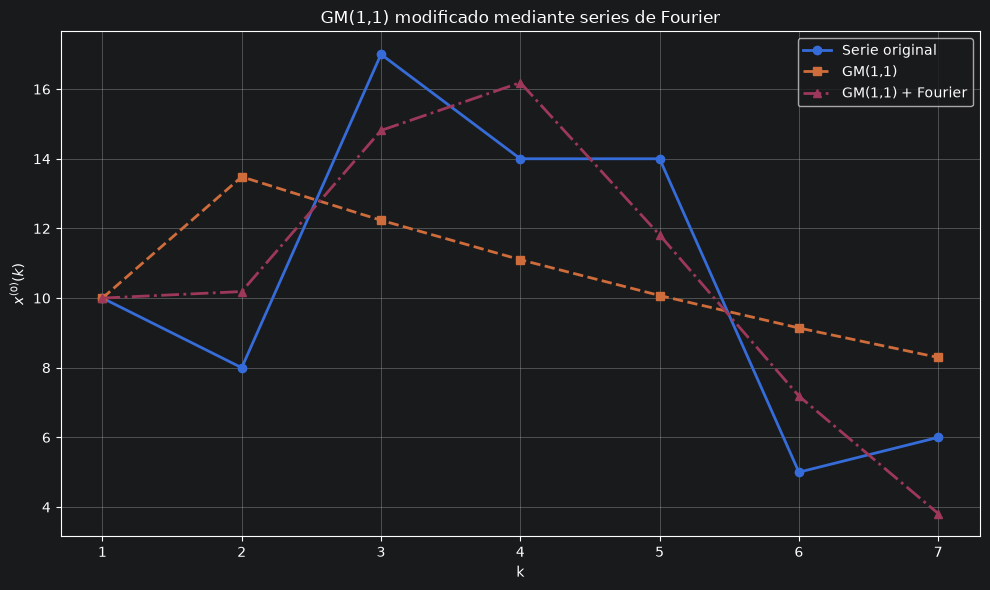

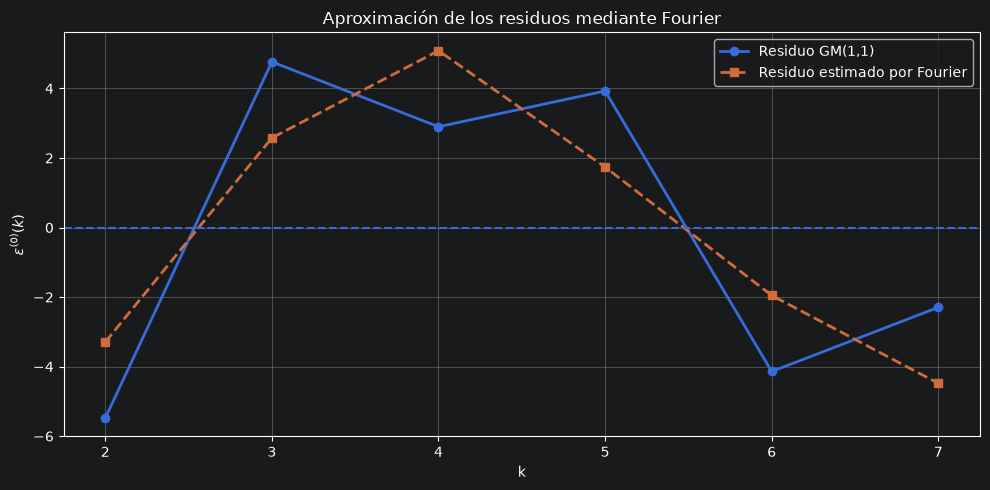

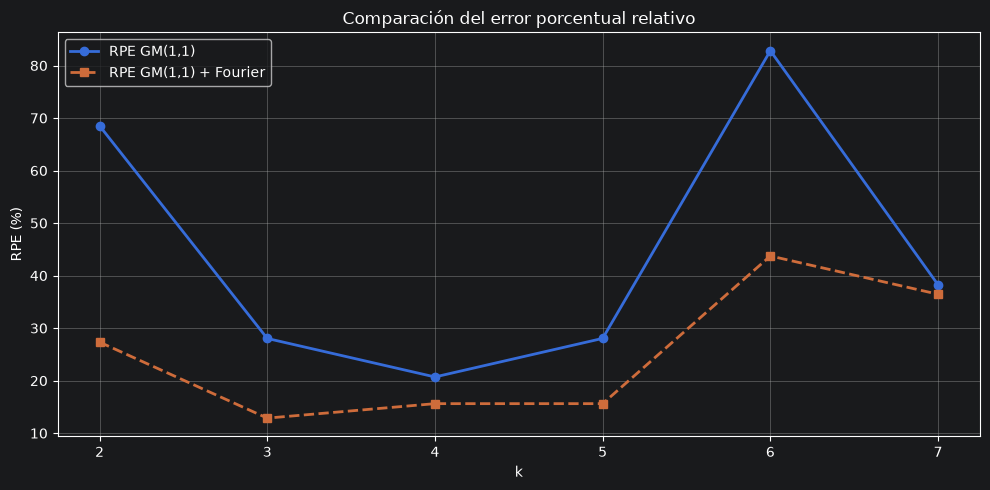


PREDICCIÓN FUTURA (Siguiente periodo)
Predicción GM(1,1) base : 8.294859
Ajuste estimado Fourier : -3.295298
PREDICCIÓN TOTAL        : 4.999561


In [42]:
    # ============================================================
    # GM(1,1) MODIFICADO MEDIANTE SERIES DE FOURIER
    # Corrección de los residuos del error
    # Ecuaciones (22) - (30)
    # ============================================================

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt


    # ============================================================
    # 1. SERIE ORIGINAL X^(0)
    # ============================================================

    X0 = ultimos.to_numpy(dtype=float)


    n = len(X0)

    print("Serie original X^(0):")
    print(X0)


    # ============================================================
    # 2. AGO
    #
    # X^(1)(k) = sum X^(0)(i)
    # ============================================================

    X1 = np.cumsum(X0)

    print("\nSerie acumulada X^(1):")
    print(X1)


    # ============================================================
    # 3. SECUENCIA DE VALORES MEDIOS Z^(1)
    #
    # z^(1)(k) =
    # 0.5*x^(1)(k) + 0.5*x^(1)(k-1)
    # ============================================================

    Z1 = 0.5 * (X1[1:] + X1[:-1])

    print("\nSecuencia Z^(1):")
    print(Z1)


    # ============================================================
    # 4. CONSTRUIR B Y Y
    # ============================================================

    B = np.column_stack((
        -Z1,
        np.ones(n - 1)
    ))

    Y = X0[1:].reshape(-1, 1)


    # ============================================================
    # 5. ESTIMAR a Y b
    # ============================================================

    parametros = np.linalg.lstsq(
        B,
        Y,
        rcond=None
    )[0]

    a = parametros[0, 0]
    b = parametros[1, 0]

    print("\n========================================")
    print("PARÁMETROS GM(1,1)")
    print("========================================")

    print(f"a = {a:.10f}")
    print(f"b = {b:.10f}")


    # ============================================================
    # 6. PREDICCIÓN GM(1,1)
    #
    # Ecuación (22)
    #
    # x_p^(0)(k+1) =
    #
    # [x^(0)(1)-b/a] exp(-ak)(1-exp(a))
    # ============================================================

    k_modelo = np.arange(1, n)

    X0_pred_restante = (
        (X0[0] - b/a)
        * np.exp(-a * k_modelo)
        * (1 - np.exp(a))
    )

    # Primer dato = condición inicial
    X0_pred = np.concatenate((
        [X0[0]],
        X0_pred_restante
    ))

    print("\nPredicción GM(1,1):")
    print(X0_pred)


    # ============================================================
    # 7. RESIDUOS
    #
    # Ecuaciones (23) y (24)
    #
    # epsilon(k) = x(k) - xp(k)
    #
    # k = 2,...,n
    # ============================================================

    epsilon = X0[1:] - X0_pred[1:]

    print("\n========================================")
    print("RESIDUOS DEL GM(1,1)")
    print("========================================")

    print(epsilon)


    # ============================================================
    # 8. PARÁMETROS DE LA SERIE DE FOURIER
    #
    # Ecuación (25)
    #
    # T = n - 1
    #
    # z = ((n - 1)/2) - 1
    #
    # z debe ser entero
    # ============================================================

    T = n - 1

    z = int((n - 1) / 2 - 1)

    print("\n========================================")
    print("PARÁMETROS DE FOURIER")
    print("========================================")

    print(f"T = {T}")
    print(f"z = {z}")


    # ============================================================
    # 9. CONSTRUIR MATRIZ P
    #
    # epsilon ≈ P C
    #
    # C = [a0, a1, b1, a2, b2, ...]^T
    # ============================================================

    # Según el artículo:
    # k = 2,3,...,n

    k_fourier = np.arange(2, n + 1)

    columnas_P = []

    # Primera columna = 1/2
    columnas_P.append(
        0.5 * np.ones(len(k_fourier))
    )


    # Añadir:
    #
    # cos(2*pi*i*k/T)
    # sin(2*pi*i*k/T)

    for i in range(1, z + 1):

        columna_cos = np.cos(
            2 * np.pi * i * k_fourier / T
        )

        columna_sin = np.sin(
            2 * np.pi * i * k_fourier / T
        )

        columnas_P.append(columna_cos)
        columnas_P.append(columna_sin)


    P = np.column_stack(columnas_P)


    print("\nMatriz P:")
    print(P)


    # ============================================================
    # 10. CALCULAR COEFICIENTES DE FOURIER
    #
    # Ecuación (29)
    #
    # C ≈ (P^T P)^(-1) P^T epsilon
    #
    # Usamos lstsq por estabilidad numérica.
    # ============================================================

    C = np.linalg.lstsq(
        P,
        epsilon,
        rcond=None
    )[0]


    print("\n========================================")
    print("COEFICIENTES DE FOURIER")
    print("========================================")

    print(C)


    # ============================================================
    # 11. ESTIMACIÓN DE LOS RESIDUOS MEDIANTE FOURIER
    #
    # epsilon_hat = P C
    # ============================================================

    epsilon_fourier = P @ C


    print("\nResiduos originales:")
    print(epsilon)

    print("\nResiduos estimados por Fourier:")
    print(epsilon_fourier)


    # ============================================================
    # 12. CORRECCIÓN DEL GM(1,1)
    # ============================================================

    # Si:
    #
    # epsilon = X_real - X_pred
    #
    # entonces:
    #
    # X_real = X_pred + epsilon
    #
    # Por ello usamos:
    #
    # X_corregido = X_pred + epsilon_fourier


    X0_fourier = X0_pred.copy()

    X0_fourier[1:] = (
        X0_pred[1:]
        + epsilon_fourier
    )


    print("\n========================================")
    print("GM(1,1) CORREGIDO POR FOURIER")
    print("========================================")

    print(X0_fourier)


    # ============================================================
    # 13. ERROR DEL GM(1,1) ORIGINAL
    # ============================================================

    error_GM = (
        X0[1:]
        - X0_pred[1:]
    )

    RPE_GM = (
        np.abs(error_GM)
        / np.abs(X0[1:])
    ) * 100

    ARPE_GM = np.mean(RPE_GM)


    # ============================================================
    # 14. ERROR DEL GM(1,1) + FOURIER
    # ============================================================

    error_Fourier = (
        X0[1:]
        - X0_fourier[1:]
    )

    RPE_Fourier = (
        np.abs(error_Fourier)
        / np.abs(X0[1:])
    ) * 100

    ARPE_Fourier = np.mean(RPE_Fourier)


    # ============================================================
    # 15. RESULTADOS
    # ============================================================

    print("\n========================================")
    print("COMPARACIÓN DE ERRORES")
    print("========================================")

    print(f"ARPE GM(1,1)          = {ARPE_GM:.6f} %")

    print(
        f"ARPE GM(1,1)+Fourier  = "
        f"{ARPE_Fourier:.6f} %"
    )


    # ============================================================
    # 16. TABLA COMPARATIVA
    # ============================================================

    k = np.arange(1, n + 1)

    tabla = pd.DataFrame({

        'k': k,

        'X original': X0,

        'GM(1,1)': X0_pred,

        'GM(1,1)+Fourier': X0_fourier

    })


    print("\n========================================")
    print("TABLA COMPARATIVA")
    print("========================================")

    print(tabla.to_string(index=False))


    # ============================================================
    # 17. GRÁFICA COMPARATIVA
    # ============================================================

    plt.figure(figsize=(10, 6))


    plt.plot(
        k,
        X0,
        marker='o',
        linewidth=2,
        label='Serie original'
    )


    plt.plot(
        k,
        X0_pred,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='GM(1,1)'
    )


    plt.plot(
        k,
        X0_fourier,
        marker='^',
        linestyle='-.',
        linewidth=2,
        label='GM(1,1) + Fourier'
    )


    plt.xlabel('k')

    plt.ylabel(r'$x^{(0)}(k)$')

    plt.title(
        'GM(1,1) modificado mediante series de Fourier'
    )

    plt.xticks(k)

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    # ============================================================
    # 18. GRÁFICA DE LOS RESIDUOS
    # ============================================================

    plt.figure(figsize=(10, 5))


    plt.plot(
        k[1:],
        epsilon,
        marker='o',
        linewidth=2,
        label='Residuo GM(1,1)'
    )


    plt.plot(
        k[1:],
        epsilon_fourier,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='Residuo estimado por Fourier'
    )


    plt.axhline(
        y=0,
        linestyle='--'
    )


    plt.xlabel('k')

    plt.ylabel(r'$\varepsilon^{(0)}(k)$')

    plt.title(
        'Aproximación de los residuos mediante Fourier'
    )

    plt.xticks(k[1:])

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    # ============================================================
    # 19. GRÁFICA RPE
    # ============================================================

    plt.figure(figsize=(10, 5))


    plt.plot(
        k[1:],
        RPE_GM,
        marker='o',
        linewidth=2,
        label='RPE GM(1,1)'
    )


    plt.plot(
        k[1:],
        RPE_Fourier,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='RPE GM(1,1) + Fourier'
    )


    plt.xlabel('k')

    plt.ylabel('RPE (%)')

    plt.title(
        'Comparación del error porcentual relativo'
    )

    plt.xticks(k[1:])

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()
    
    
    # ============================================================
    # 20. PREDICCIÓN DEL SIGUIENTE PASO (FUTURO)
    # ============================================================

    # 1. k para el modelo base GM(1,1)
    # Dado que n = len(X0) + 1, el siguiente paso futuro evaluado en la ecuación es n - 1
    k_futuro_gm = n - 1

    pred_gm11_futuro = (
        (X0[0] - b/a)
        * np.exp(-a * k_futuro_gm)
        * (1 - np.exp(a))
    )

    # 2. k para el modelo de Fourier
    # Siguiendo la secuencia k_fourier que termina en n, el siguiente paso es n + 1
    k_futuro_fourier = n + 1

    fila_P_futuro = [0.5]
    for i in range(1, z + 1):
        fila_P_futuro.append(np.cos(2 * np.pi * i * k_futuro_fourier / T))
        fila_P_futuro.append(np.sin(2 * np.pi * i * k_futuro_fourier / T))

    fila_P_futuro = np.array(fila_P_futuro)

    # Multiplicamos la matriz (fila) P del futuro por los coeficientes C
    residuo_futuro = np.dot(fila_P_futuro, C)

    # Extraemos el valor numérico si C se guardó como un array 2D/1D
    if isinstance(residuo_futuro, np.ndarray):
        residuo_futuro = residuo_futuro.item()

    # 3. Predicción final sumando el modelo GM(1,1) base y el residuo corregido
    pred_final_futuro = pred_gm11_futuro + residuo_futuro

    print("\n========================================")
    print("PREDICCIÓN FUTURA (Siguiente periodo)")
    print("========================================")
    print(f"Predicción GM(1,1) base : {pred_gm11_futuro:.6f}")
    print(f"Ajuste estimado Fourier : {residuo_futuro:.6f}")
    print(f"PREDICCIÓN TOTAL        : {pred_final_futuro:.6f}")